# 逕流歷線計算

參考「出流管制技術手冊_1150901」與「全台雨量站降雨強度延時公式推導 (114年校核版)」

In [25]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from pathlib import Path
import os

current_dir = Path().cwd()
data_dir = current_dir.parent / 'data'
output_dir = current_dir.parent / 'outputs'

df_honer_factor = pd.read_csv(data_dir / 'Honer_factor.csv', encoding='utf-8-sig')
df_honer_factor["流域編號"] = df_honer_factor["流域編號"].astype(str)
df_honer_factor["測站編號"] = df_honer_factor["測站編號"].astype(str)
df_honer_factor["重現期距(年)"] = df_honer_factor["重現期距(年)"].astype(str)

display(df_honer_factor.head())

,流域編號,流域,測站編號,測站,重現期距(年),理論分布,理論分布英文縮寫,a,b,c
0,165000,鹽水溪,467410,臺南,2,二參數對數常態,LN2,712.239,14.433,0.608
1,165000,鹽水溪,467410,臺南,2,三參數對數常態,LN3,906.325,15.077,0.623
2,165000,鹽水溪,467410,臺南,2,皮爾遜三型,PT3,926.394,14.660,0.626
3,165000,鹽水溪,467410,臺南,2,對數皮爾遜三型,LPT3,866.174,14.272,0.609
4,165000,鹽水溪,467410,臺南,2,極端值一型,EV1,701.136,14.465,0.600


In [18]:
# 使用者輸入欲查詢之「測站編號」、「重現期距(年)」、「理論分布英文縮寫」，自動查詢對應之 Honer 參數
station_id = str(input("請輸入測站編號: "))
return_period = str(input(f"請輸入重現期距({', '.join(df_honer_factor['重現期距(年)'].unique())}): "))
theoretical_distribution = str(input(f"請輸入理論分布英文縮寫({', '.join(df_honer_factor['理論分布英文縮寫'].unique())}): "))

df_honer_filtered = df_honer_factor[(df_honer_factor['測站編號'] == station_id) &
                          (df_honer_factor['重現期距(年)'] == return_period) &
                          (df_honer_factor['理論分布英文縮寫'] == theoretical_distribution)]

HONER_FACTOR = df_honer_filtered[['a', 'b', 'c']].values.flatten()

In [26]:
print(f"查詢結果：\n流域編號：{df_honer_filtered['流域編號'].iloc[0]}, 流域名稱：{df_honer_filtered['流域'].iloc[0]}, 測站編號：{station_id}, 測站名稱：{df_honer_filtered['測站'].iloc[0]}, 重現期距：{return_period} 年, 理論分布：{df_honer_filtered['理論分布'].iloc[0]}, 理論分布英文縮寫：{theoretical_distribution} \n對應之 Honer 參數為 a={HONER_FACTOR[0]}, b={HONER_FACTOR[1]}, c={HONER_FACTOR[2]}")

查詢結果：
流域編號：165000, 流域名稱：鹽水溪, 測站編號：467410, 測站名稱：臺南, 重現期距：10 年, 理論分布：皮爾遜三型, 理論分布英文縮寫：PT3 
對應之 Honer 參數為 a=918.319, b=16.625, c=0.548


# 設計雨型 - Honer
$I^T=\cfrac{a}{(t+b)^c}$

$R=I^T*\cfrac{t}{24}$

In [44]:
# 從 10 分鐘計算降雨強度延時 I 至 24 小時 (1440 分鐘) 的降雨強度延時 I
rows = []
prev_R = 0.0

for t in range(10, 1441, 10):
    I = float(HONER_FACTOR[0]) / (t + float(HONER_FACTOR[1])) ** float(HONER_FACTOR[2])

    R = I * t / 60
    delta_R = R - prev_R

    rows.append({
        '降雨延時 t (min)': t,
        '降雨強度 I (mm/hr)': I,
        '24 小時總降雨量 R (mm)': R,
        '降雨增量 Delta_R (mm)': delta_R
    })
    prev_R = R

df_honer = pd.DataFrame(rows).astype({
    '降雨延時 t (min)': 'int64',
    '降雨強度 I (mm/hr)': 'float64',
    '24 小時總降雨量 R (mm)': 'float64',
    '降雨增量 Delta_R (mm)': 'float64'
})

display(df_honer.round(4))

,降雨延時 t (min),降雨強度 I (mm/hr),24 小時總降雨量 R (mm),降雨增量 Delta_R (mm)
0,10,152.0319,25.3387,25.3387
1,20,127.6566,42.5522,17.2136
2,30,111.8383,55.9191,13.3669
3,40,100.5414,67.0276,11.1085
4,50,91.9688,76.6406,9.6130
...,...,...,...,...
139,1400,17.2229,401.8673,1.3185
140,1410,17.1566,403.1806,1.3133
141,1420,17.0911,404.4888,1.3082
142,1430,17.0262,405.7918,1.3030


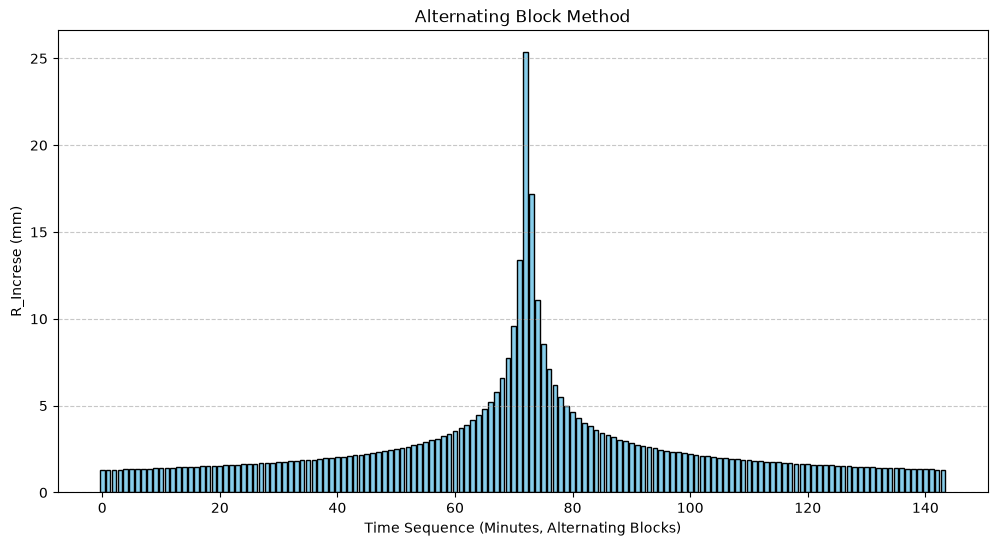

In [45]:
# 1. 取得 Increse 欄位並由大到小排序
increse_sorted = df_honer["降雨增量 Delta_R (mm)"].sort_values(ascending=False).values

# 2. 實作交替區塊法 (Alternating Block Method)
n = len(increse_sorted)
alternating_blocks = [0] * n

# 設中心點
mid = n // 2
alternating_blocks[mid] = increse_sorted[0]

# 交替放置左右兩側
left = mid - 1
right = mid + 1
for i in range(1, n):
    if i % 2 == 1:
        if right < n:
            alternating_blocks[right] = increse_sorted[i]
            right += 1
        else:
            alternating_blocks[left] = increse_sorted[i]
            left -= 1
    else:
        if left >= 0:
            alternating_blocks[left] = increse_sorted[i]
            left -= 1
        else:
            alternating_blocks[right] = increse_sorted[i]
            right += 1

# 3. 繪製交替區塊法結果圖
plt.figure(figsize=(12, 6))

plt.bar(range(n), alternating_blocks, color='skyblue', edgecolor='black', width=0.8)
plt.xlabel('Time Sequence (Minutes, Alternating Blocks)')
plt.ylabel('R_Increse (mm)')
plt.title('Alternating Block Method')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# 有效降雨量計算

,Distribution,t (mins),R (mm),P (mm),R_Increse (mm)
0,PT3,10,25.338658,25.338658,25.338658
1,PT3,20,42.552215,67.890873,17.213557
2,PT3,30,55.919135,123.810008,13.366920
3,PT3,40,67.027622,190.837630,11.108486
4,PT3,50,76.640641,267.478271,9.613019
5,PT3,60,85.184101,352.662371,8.543460
6,PT3,70,92.920569,445.582940,7.736468
7,PT3,80,100.023779,545.606719,7.103210
8,PT3,90,106.614942,652.221660,6.591163
9,PT3,100,112.782182,765.003842,6.167240


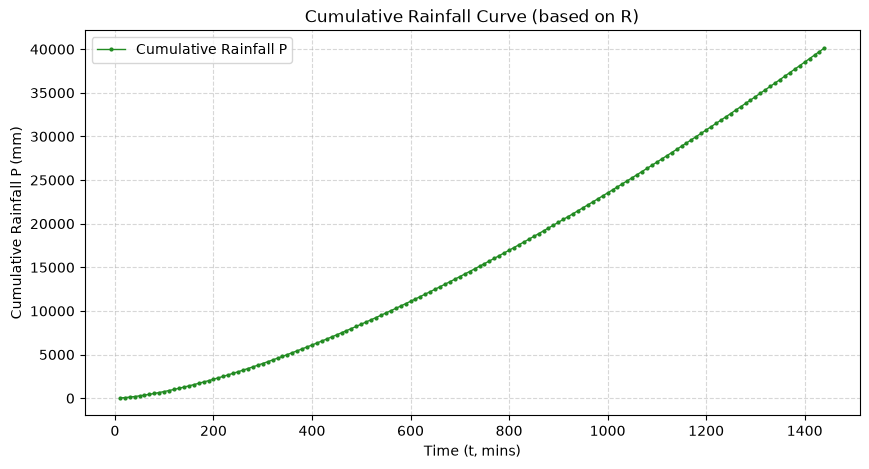

In [3]:
# 1. 使用 'R (mm)' 欄位計算累計降雨量，並新增為欄位 'P'
df['P (mm)'] = df['R (mm)'].cumsum()

# 2. 顯示計算後的 DataFrame 前幾列
display(df[['Distribution', 't (mins)', 'R (mm)', 'P (mm)', 'R_Increse (mm)']].head(15))

# 3. 繪製時間 (t) 與累積降雨量 (P) 的變化圖
plt.figure(figsize=(10, 5))
plt.plot(df['t (mins)'], df['P (mm)'], marker='o', color='forestgreen', linestyle='-', linewidth=1, label='Cumulative Rainfall P', markersize=2)
plt.xlabel('Time (t, mins)')
plt.ylabel('Cumulative Rainfall P (mm)')
plt.title('Cumulative Rainfall Curve (based on R)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

,t (mins),R (mm),P (mm),Pe (mm)
0,10,25.338658,25.338658,0.113188
1,20,42.552215,67.890873,13.724674
2,30,55.919135,123.810008,49.369763
3,40,67.027622,190.837630,102.846274
4,50,76.640641,267.478271,170.270684
5,60,85.184101,352.662371,248.980768
6,70,92.920569,445.582940,337.200614
7,80,100.023779,545.606719,433.707433
8,90,106.614942,652.221660,537.621439
9,100,112.782182,765.003842,648.282116


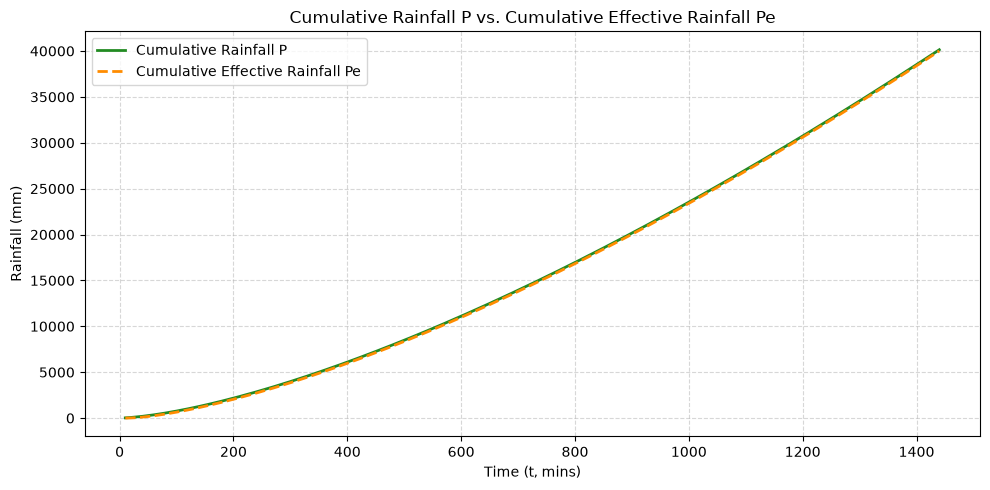

In [4]:
S = 25.4*(1000/70-10)
Ia = 0.2 * S # 初始損失量 (21.7714 mm)

# 計算 Pe (mm)：當 P < Ia 時 Pe 應為 0，否則套用公式
df['Pe (mm)'] = np.where(
    df['P (mm)'] < Ia,
    0,
    ((df['P (mm)'] - Ia) ** 2) / (df['P (mm)'] + 0.8 * S)
)

# 顯示包含 R, P, Pe 欄位的前幾行資料
display(df[['t (mins)', 'R (mm)', 'P (mm)', 'Pe (mm)']].head(15))

# 繪製累積降雨量 P 與累積有效降雨量 Pe 的對比圖
plt.figure(figsize=(10, 5))
plt.plot(df['t (mins)'], df['P (mm)'], '-', color='forestgreen', linewidth=2, label='Cumulative Rainfall P')
plt.plot(df['t (mins)'], df['Pe (mm)'], '--', color='darkorange', linewidth=2, label='Cumulative Effective Rainfall Pe')
plt.xlabel('Time (t, mins)')
plt.ylabel('Rainfall (mm)')
plt.title('Cumulative Rainfall P vs. Cumulative Effective Rainfall Pe')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.legend()
plt.show()

In [ ]:
# df.to_csv(output_dir / 'Honer_output_PT3_10y.csv', index=False, encoding='utf-8-sig')